Universidad del Valle de Guatemala  
Departamento de Ciencias de la Computación  
CC2017 Modelación y Simulación

# 01. Dinámica de sistemas. Caja, inventario y deuda

La dinámica de sistemas describe un negocio con stocks, que son cantidades que se acumulan, y con flujos, que los llenan o los vacían cada mes. En este notebook los stocks son la caja, el inventario y la deuda de una cafetería tipo. Se responde cuántos meses aguanta el negocio si sus ventas son 30 % menores a lo esperado.

## 1. Parámetros del negocio

Los valores de `BusinessParams` son supuestos creíbles para una cafetería pequeña en Guatemala, en quetzales. Los clientes de equilibrio son los que cubren los costos fijos y la cuota de la deuda con el margen de cada venta.

In [1]:
import sys

import matplotlib.pyplot as plt
import pandas as pd

sys.path.append("../src")
from business_sim.finance import demand_curve, months_survived, simulate_finance
from business_sim.params import BusinessParams

p = BusinessParams()
pd.Series({
    "Caja inicial (Q)": p.initial_cash,
    "Ticket promedio (Q)": p.avg_ticket,
    "Costo de insumos por cliente (Q)": p.unit_cost,
    "Costos fijos mensuales (Q)": p.fixed_costs,
    "Cuota mensual de la deuda (Q)": round(p.loan_payment, 2),
    "Deuda inicial (Q)": p.loan_amount,
    "Clientes de equilibrio por mes": round(p.breakeven_customers),
    "Clientes esperados mes 1": p.demand_start,
    "Clientes esperados al madurar": p.demand_mature,
}).to_frame("Valor")

,Valor
Caja inicial (Q),60000.00
Ticket promedio (Q),45.00
Costo de insumos por cliente (Q),15.00
Costos fijos mensuales (Q),27000.00
Cuota mensual de la deuda (Q),3615.24
Deuda inicial (Q),100000.00
Clientes de equilibrio por mes,1021.00
Clientes esperados mes 1,700.00
Clientes esperados al madurar,1600.00


Cada cliente deja Q30 de margen. Se necesitan 1 021 clientes al mes para cubrir Q27 000 de costos fijos y Q3 615 de cuota. El negocio abre con 700 clientes esperados, por debajo de ese umbral.

## 2. Demanda esperada

La demanda crece desde 700 clientes hacia 1 600, y la mitad de ese crecimiento ocurre en el mes 6. Sobre esa curva se aplica una estacionalidad con pico en diciembre. El escenario bajo multiplica toda la curva por 0.7.

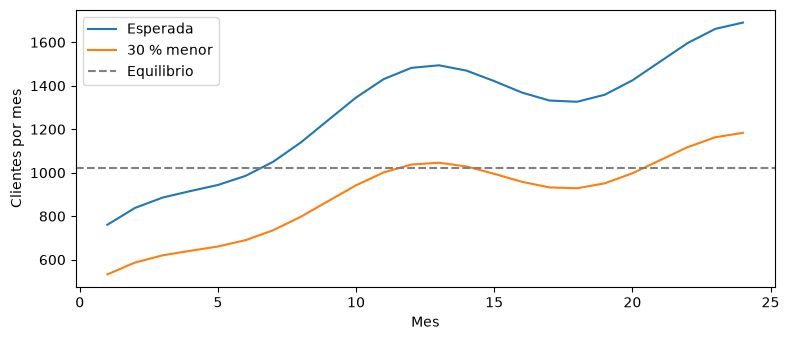

In [2]:
esperada = demand_curve(p)
baja = demand_curve(p, factor=0.7)

meses = range(1, p.horizon + 1)
plt.figure(figsize=(8, 3.5))
plt.plot(meses, esperada, label="Esperada")
plt.plot(meses, baja, label="30 % menor")
plt.axhline(p.breakeven_customers, color="gray", ls="--", label="Equilibrio")
plt.xlabel("Mes")
plt.ylabel("Clientes por mes")
plt.legend()
plt.tight_layout()
plt.show()

La demanda esperada supera el equilibrio desde el mes 7. La demanda 30 % menor solo lo supera en los meses 12 a 14 y desde el mes 21.

## 3. Simulación de los stocks

En cada mes se compra inventario según la demanda del mes anterior, se atienden los clientes, se descuenta la merma y se pagan los costos fijos y la cuota. Los meses que aguanta son los meses completos antes de que la caja sea negativa.

In [3]:
escenarios = {"Esperada": simulate_finance(p, esperada), "30 % menor": simulate_finance(p, baja)}

pd.DataFrame({
    nombre: {
        "Meses que aguanta": months_survived(df),
        "Caja mínima (Q)": round(df["cash"].min()),
        "Mes de caja mínima": int(df["cash"].idxmin()),
        "Caja final (Q)": round(df["cash"].iloc[-1]),
    }
    for nombre, df in escenarios.items()
})

,Esperada,30 % menor
Meses que aguanta,24,5
Caja mínima (Q),41537,-40107
Mes de caja mínima,6,20
Caja final (Q),245444,-28408


Con la demanda esperada la caja baja hasta Q41 537 en el mes 6 y luego crece hasta Q245 444. Con ventas 30 % menores la caja es negativa desde el mes 6, por lo que el negocio aguanta 5 meses. El faltante más profundo es de Q40 107 en el mes 20.

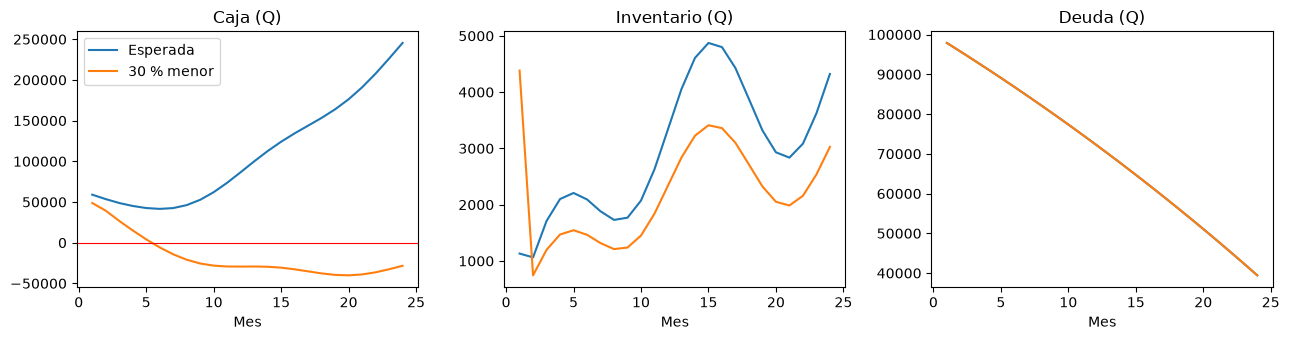

In [4]:
fig, ejes = plt.subplots(1, 3, figsize=(13, 3.5))
for nombre, df in escenarios.items():
    for eje, col in zip(ejes, ["cash", "inventory", "debt"]):
        eje.plot(df.index, df[col], label=nombre)
for eje, titulo in zip(ejes, ["Caja (Q)", "Inventario (Q)", "Deuda (Q)"]):
    eje.set_title(titulo)
    eje.set_xlabel("Mes")
ejes[0].axhline(0, color="red", lw=0.8)
ejes[0].legend()
plt.tight_layout()
plt.show()

La deuda baja igual en ambos escenarios porque la cuota es fija. El inventario sigue a la demanda y es menor en el escenario bajo, salvo en el mes 1, cuando la compra se basa en los 700 clientes esperados.

## 4. Flujos del escenario bajo

La tabla muestra ingresos y salidas de caja de algunos meses. La columna `net` es el cambio de la caja en el mes.

In [5]:
bajo = escenarios["30 % menor"].copy()
bajo["net"] = bajo["cash"].diff().fillna(bajo["cash"].iloc[0] - p.initial_cash)
flujos = ["revenue", "purchases", "fixed", "interest", "principal", "net"]
bajo.loc[[1, 6, 12, 13, 18, 24], flujos].round(0)

,revenue,purchases,fixed,interest,principal,net
month,,,,,,
1,23960.0,4600.0,27000.0,1500.0,2115.0,-11256.0
6,31040.0,10344.0,27000.0,1337.0,2279.0,-9919.0
12,46689.0,16184.0,27000.0,1124.0,2492.0,-110.0
13,47063.0,16337.0,27000.0,1086.0,2529.0,111.0
18,41780.0,13684.0,27000.0,891.0,2724.0,-2519.0
24,53252.0,18400.0,27000.0,636.0,2979.0,4237.0


En el mes 1 los ingresos son Q23 960, menos que los costos fijos de Q27 000. El flujo neto es negativo en casi todos los meses hasta el mes 20. Solo el mes 13 tiene un flujo positivo de Q111, y desde el mes 21 el flujo vuelve a ser positivo.

## 5. Meses que aguanta según la variación en ventas

Se repite la simulación con varios factores de demanda.

In [6]:
factores = [1.2, 1.1, 1.0, 0.9, 0.8, 0.75, 0.7, 0.6, 0.5]
pd.DataFrame({
    "Cambio en ventas": [f"{f - 1:+.0%}" for f in factores],
    "Meses que aguanta": [months_survived(simulate_finance(p, demand_curve(p, f))) for f in factores],
    "Caja mínima (Q)": [round(simulate_finance(p, demand_curve(p, f))["cash"].min()) for f in factores],
}).set_index("Cambio en ventas")

,Meses que aguanta,Caja mínima (Q)
Cambio en ventas,,
+20%,24,60798
+10%,24,55138
+0%,24,41537
-10%,24,23597
-20%,24,529
-25%,6,-13157
-30%,5,-40107
-40%,4,-119692
-50%,3,-210976


Con caídas de hasta 20 % el negocio aguanta los 24 meses, aunque con -20 % la caja mínima es de solo Q529. Con -25 % aguanta 6 meses, con -30 % aguanta 5 y con -50 % aguanta 3. Entre -20 % y -25 % hay un umbral marcado.

## Conclusión

Con estos supuestos la cafetería resiste caídas de ventas de hasta 20 %, y con una caída de 30 % se queda sin caja al sexto mes. El modelo trata la demanda como un dato fijo, por lo que en el siguiente notebook se obtiene de una población de clientes.